# Earthquakes in Indonesia — end-to-end run

Reproduces every number and figure in the story, from the raw archive to the story page.
Run the whole notebook from the repo root with `.venv/bin/python -m src.run`.

Counting rules: `docs/storyboard.md` §2, implemented in `src/clean.py`. Figure text: `docs/figure-text.md`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
print("repo:", ROOT.name)

repo: vdl-midterm-gempa-indonesia


## 1. Data: rebuild and verify the catalog

Fetches the author's archive and parser at a pinned commit, rebuilds `katalog_gempa_v2.tsv` and checks its SHA-256 against the author's MANIFEST (skipped when the verified files are already present).

In [2]:
from src import download

download.main()
print(open("data/raw/MANIFEST.md").read())

verified raw files already present; use --force to re-fetch and rebuild
# Raw data manifest

Written by `src/download.py`. Upstream files are fetched from the author's repository at a pinned commit; the catalog is rebuilt with the author's parser and checked against the author's MANIFEST.md.

- Repository: https://github.com/kekavigi/repo-gempa at commit `539ed6e461c409da1475781fd57bbc6deaef66ef`
- Dataset citation: Vigiliant, A. K. *Earthquakes in Indonesia*, Kaggle, DOI 10.34740/kaggle/ds/1934565
- Fetched / rebuilt (UTC): 2026-10-28 02:31

| file | role | source | SHA-256 |
|---|---|---|---|
| `upstream/bmkg_html.sqlite` | upstream input (not committed) | `https://raw.githubusercontent.com/kekavigi/repo-gempa/539ed6e461c409da1475781fd57bbc6deaef66ef/katalog_gempa_v2/bmkg_html.sqlite` | `13c5333d0d4bf15648c4c0d114771e06e595958e910a0718b500bffe93689cf2` |
| `upstream/extract_tsv.py` | upstream input (not committed) | `https://raw.githubusercontent.com/kekavigi/repo-gempa/539ed6e461c40

## 2. Analysis table and valid days

In [3]:
from src import clean

clean.main()

gempa_box.csv: 144,030 events in box | valid_days.csv: 6,496 days (6,353 ok, 143 broken)


## 3. Profiling and number check

`reports/profiling.md` (descriptive facts) and `reports/number_check.md` (every number in the final brief, storyboard, figure text and Q&A notes, recomputed).

In [4]:
from src import profiling, number_check

profiling.main()
number_check.main()

wrote reports/profiling.md (54 lines)


wrote reports/number_check.md: {'match': 94, 'close': 7, 'n.a.': 2, 'differs': 2}


## 4. BMKG release figures for Figure 1

Typed from press reports; `total_source` / `m5_source` are the source numbers in storyboard §6.

In [5]:
display(pd.read_csv("data/raw/bmkg_releases.csv"))
display(pd.read_csv("data/raw/bmkg_releases_second_2024.csv"))

,year,total,total_source,m5,m5_source,note
0,2020,8264,3,244,3,NaN
1,2021,10570,3,244,3,NaN
2,2022,10792,4,205,4,NaN
3,2023,10789,4;5,219,4,NaN
4,2024,7358,6,186,6,year-end release (31 Des 2024)
5,2025,43439,10,153,10,NaN


,year,total,total_source,note
0,2024,29869,7;8,announced by the head of BMKG on 17 Jan 2025


## 5. Story figures

One function per figure in `src/figures.py`.

### Figure 1

figures/f1_rilis_bmkg.png


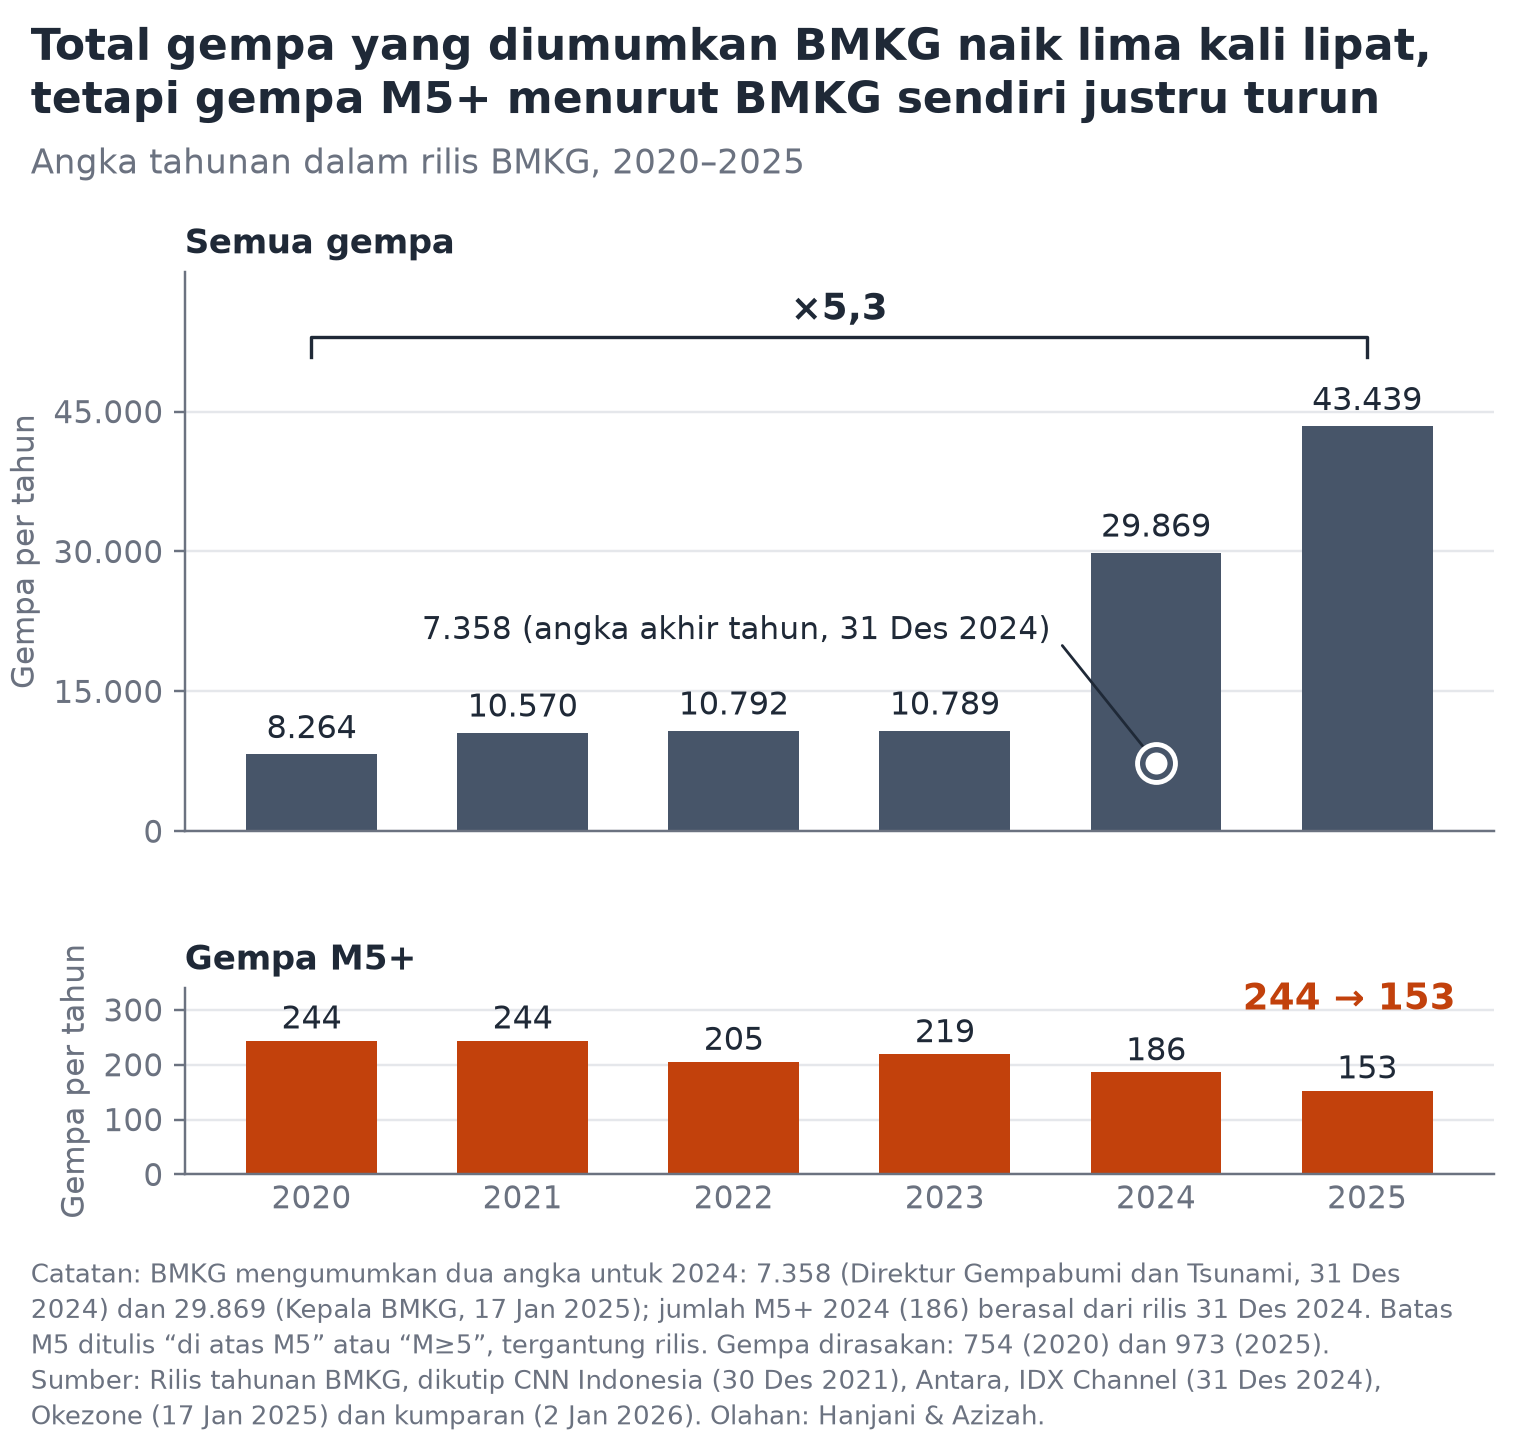

In [6]:
from src import figures

path = figures.f1()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Figure 2

figures/f2_katalog_kelas_magnitudo.png


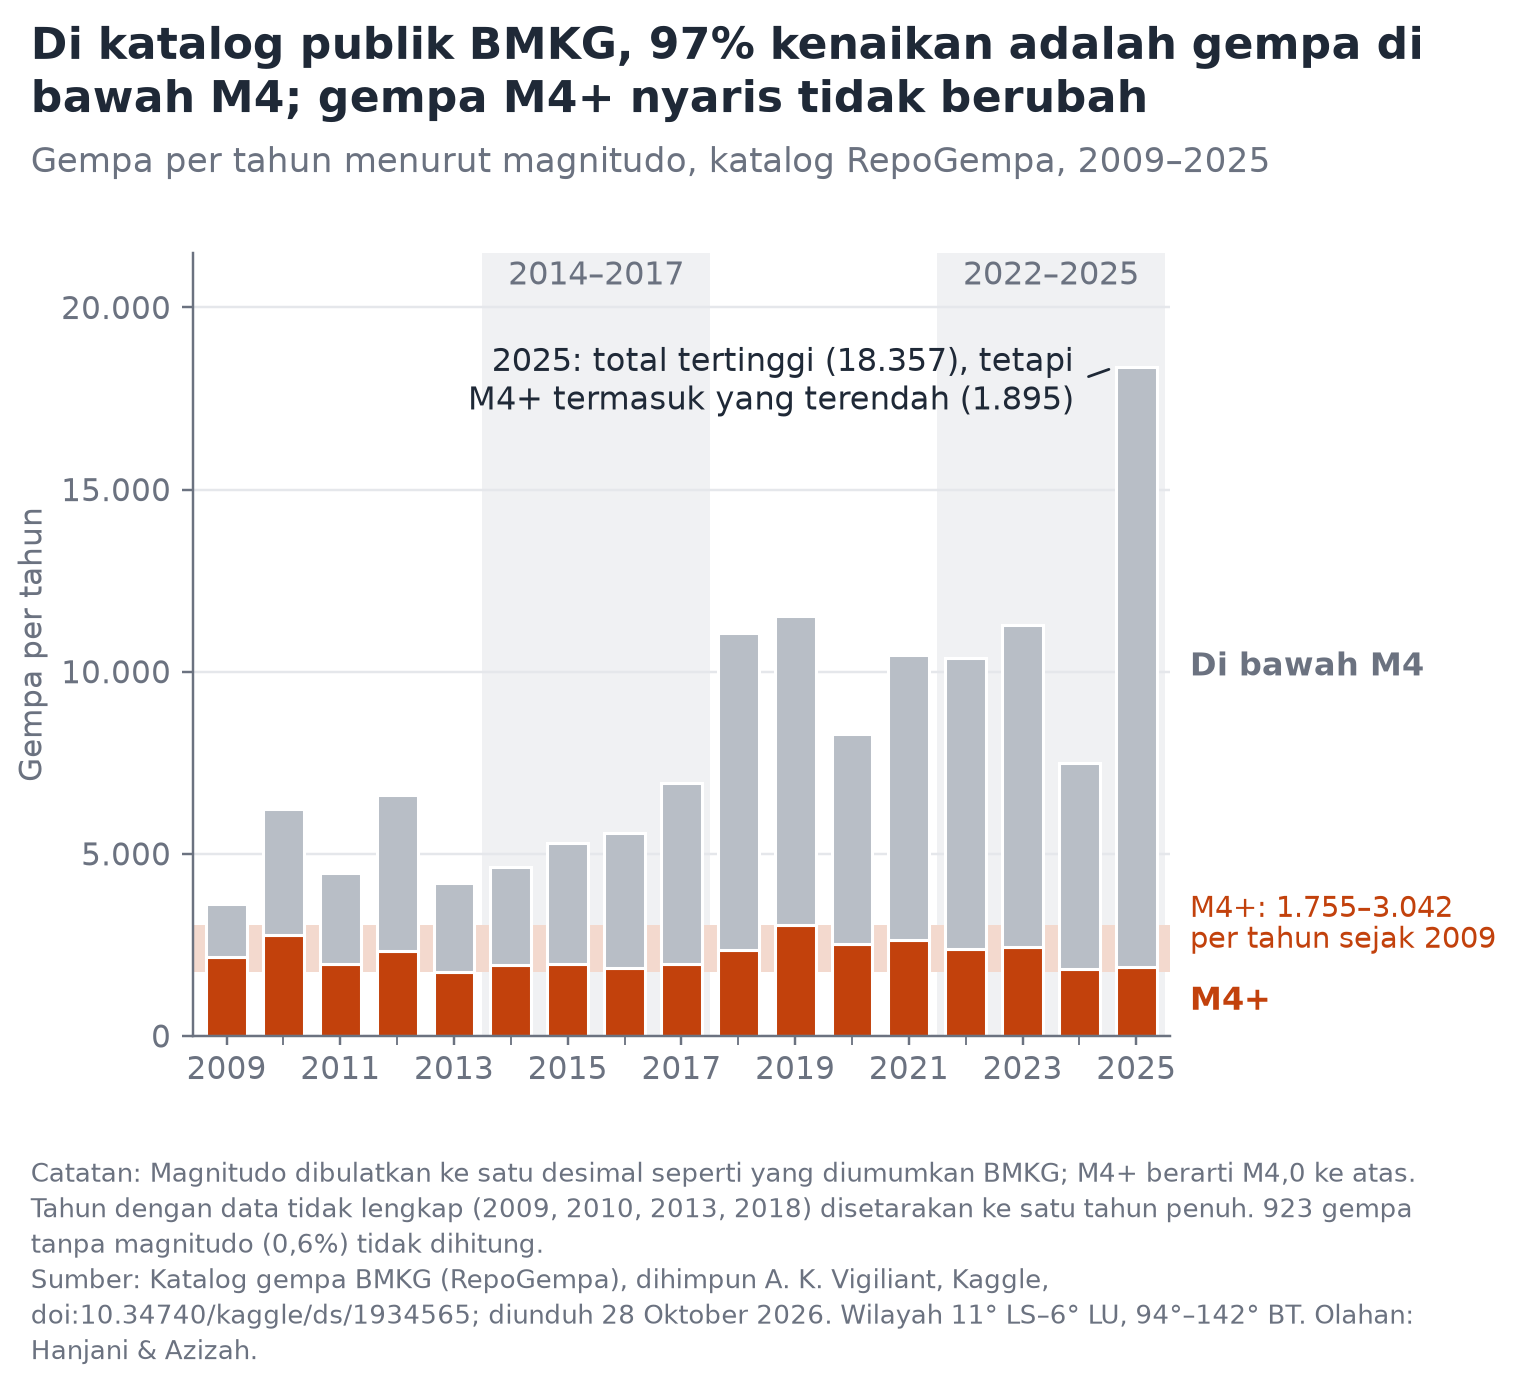

In [7]:
from src import figures

path = figures.f2()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Figure 3

figures/f3_distribusi_magnitudo.png


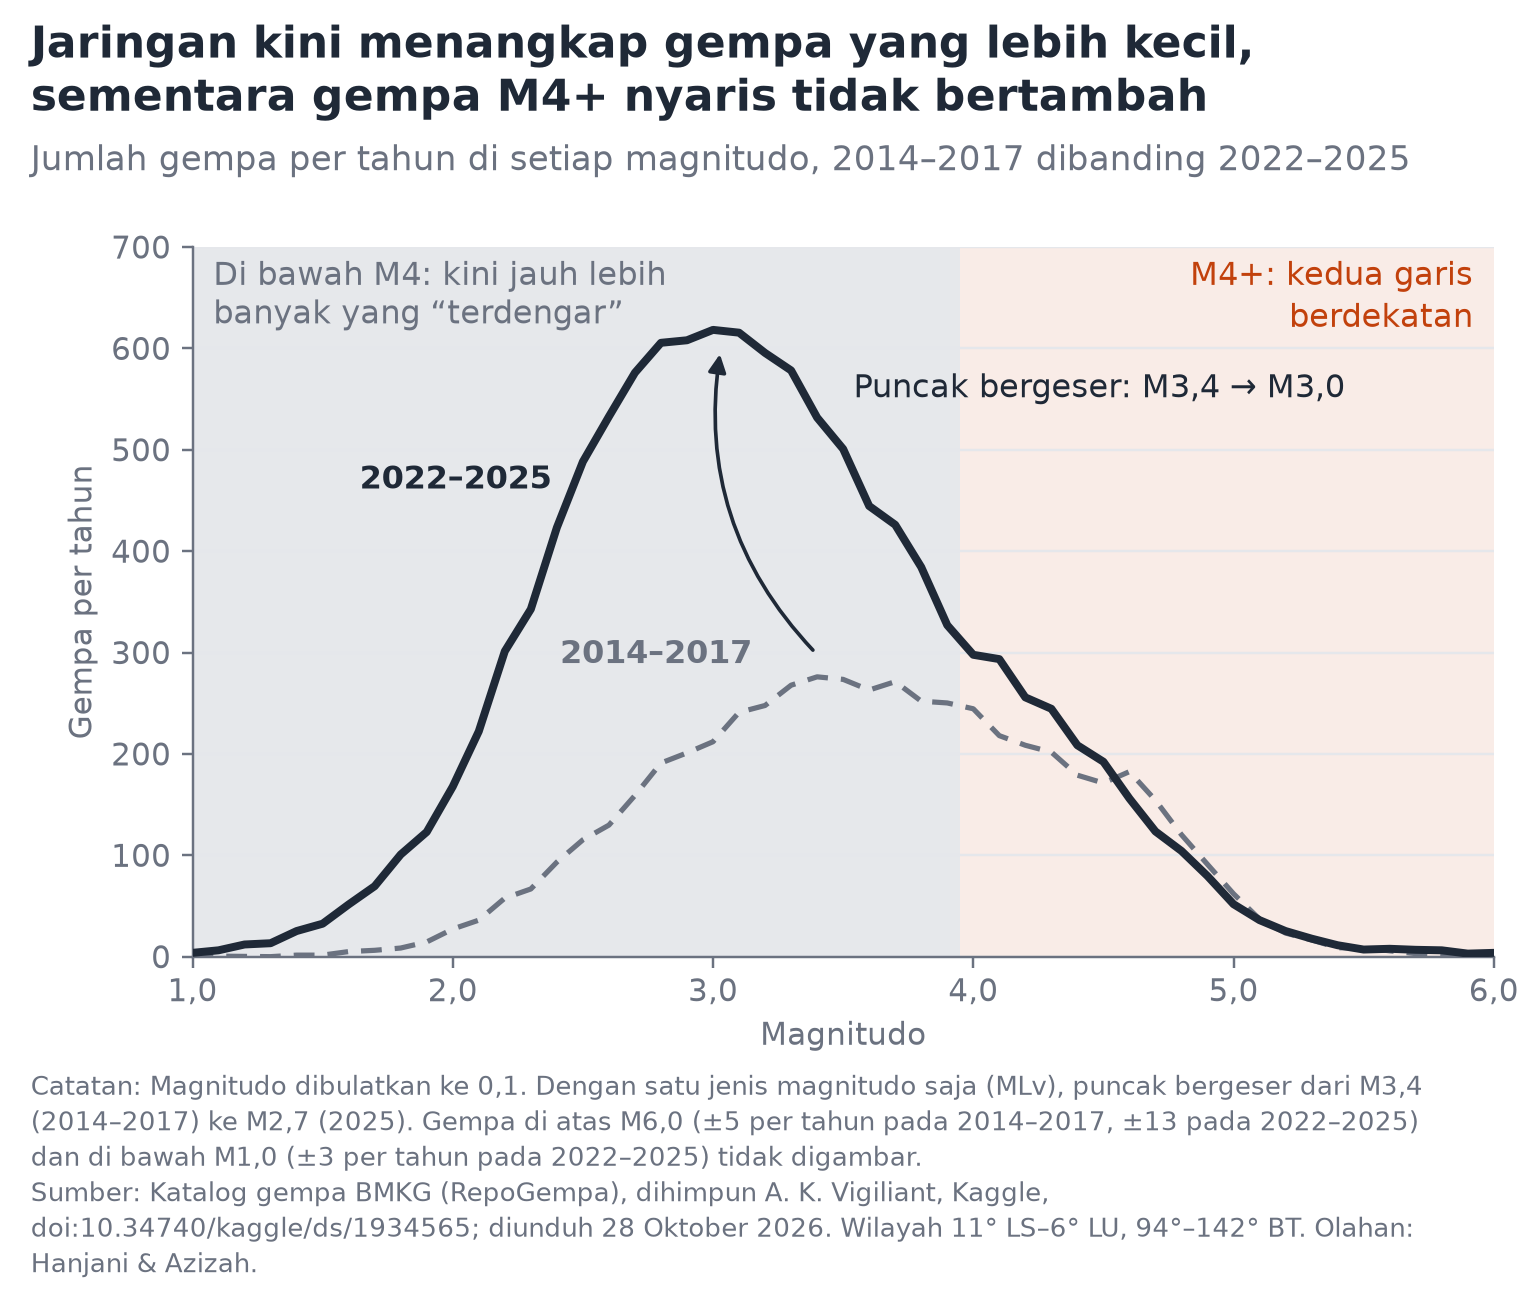

In [8]:
from src import figures

path = figures.f3()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Figure 4

figures/f4_bacaan_fase.png


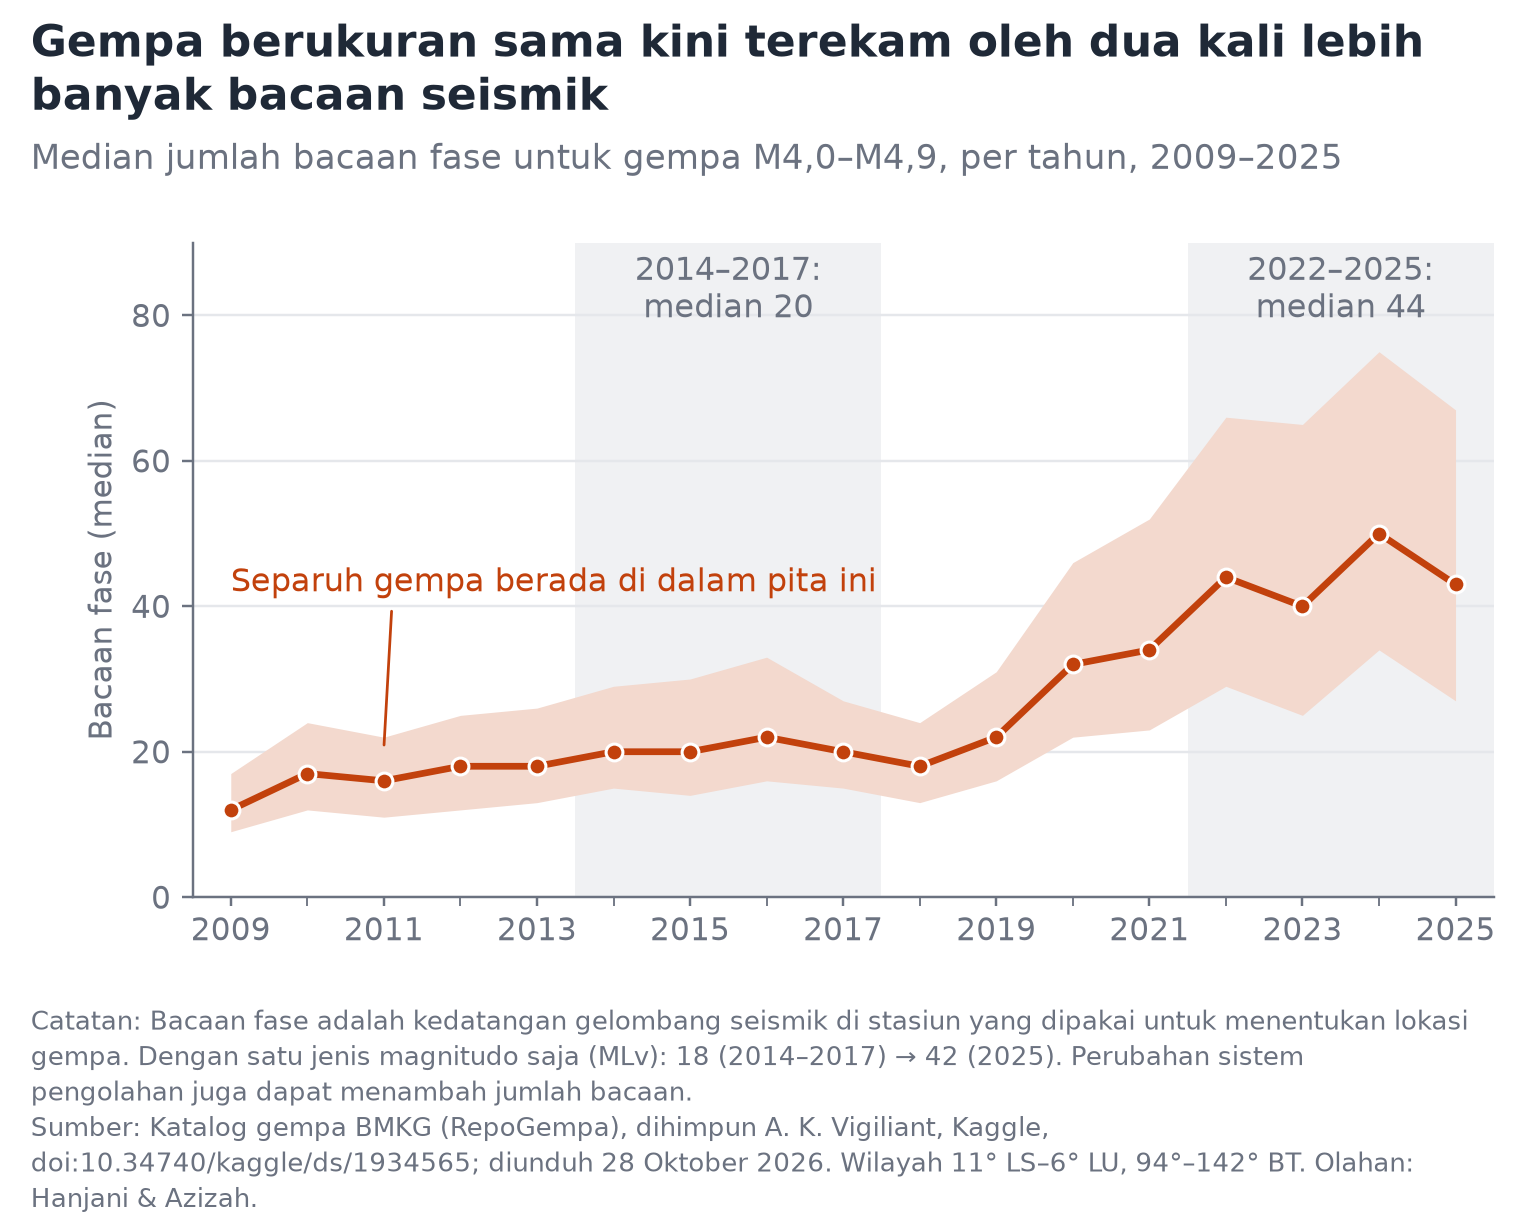

In [9]:
from src import figures

path = figures.f4()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Figure 5

figures/f5_m4_per_bulan.png


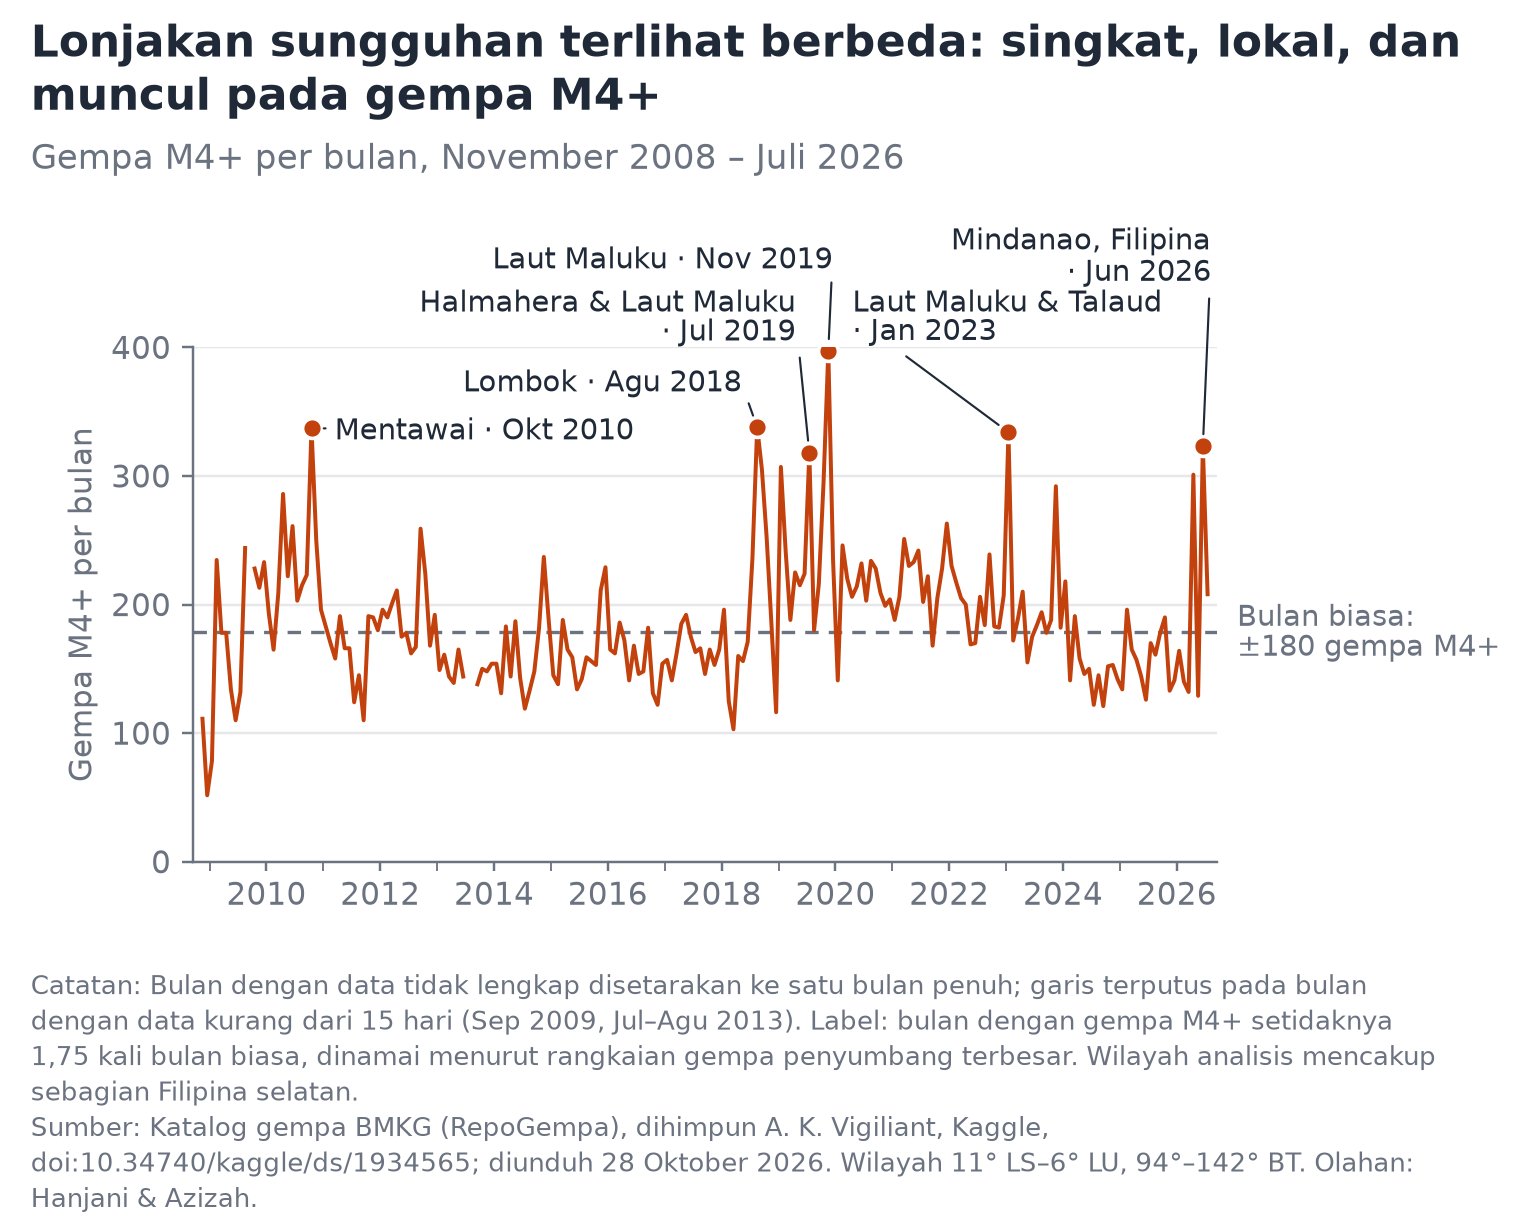

In [10]:
from src import figures

path = figures.f5()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Figure 6

figures/f6_laju_m4_2026.png


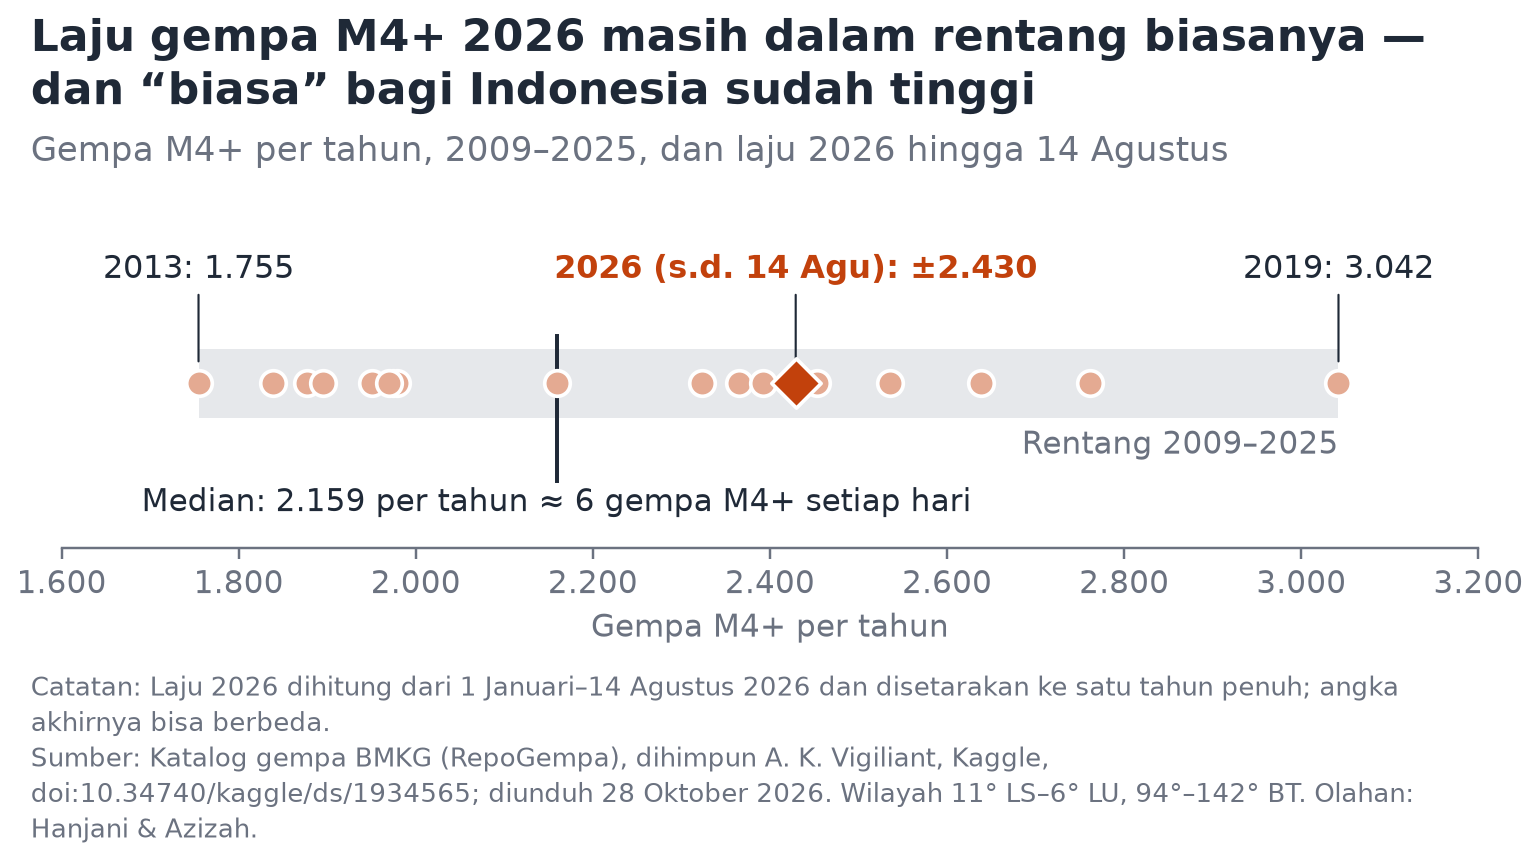

In [11]:
from src import figures

path = figures.f6()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

### Discarded figure (F-X)

figures/discarded/fx_kode_stasiun.png


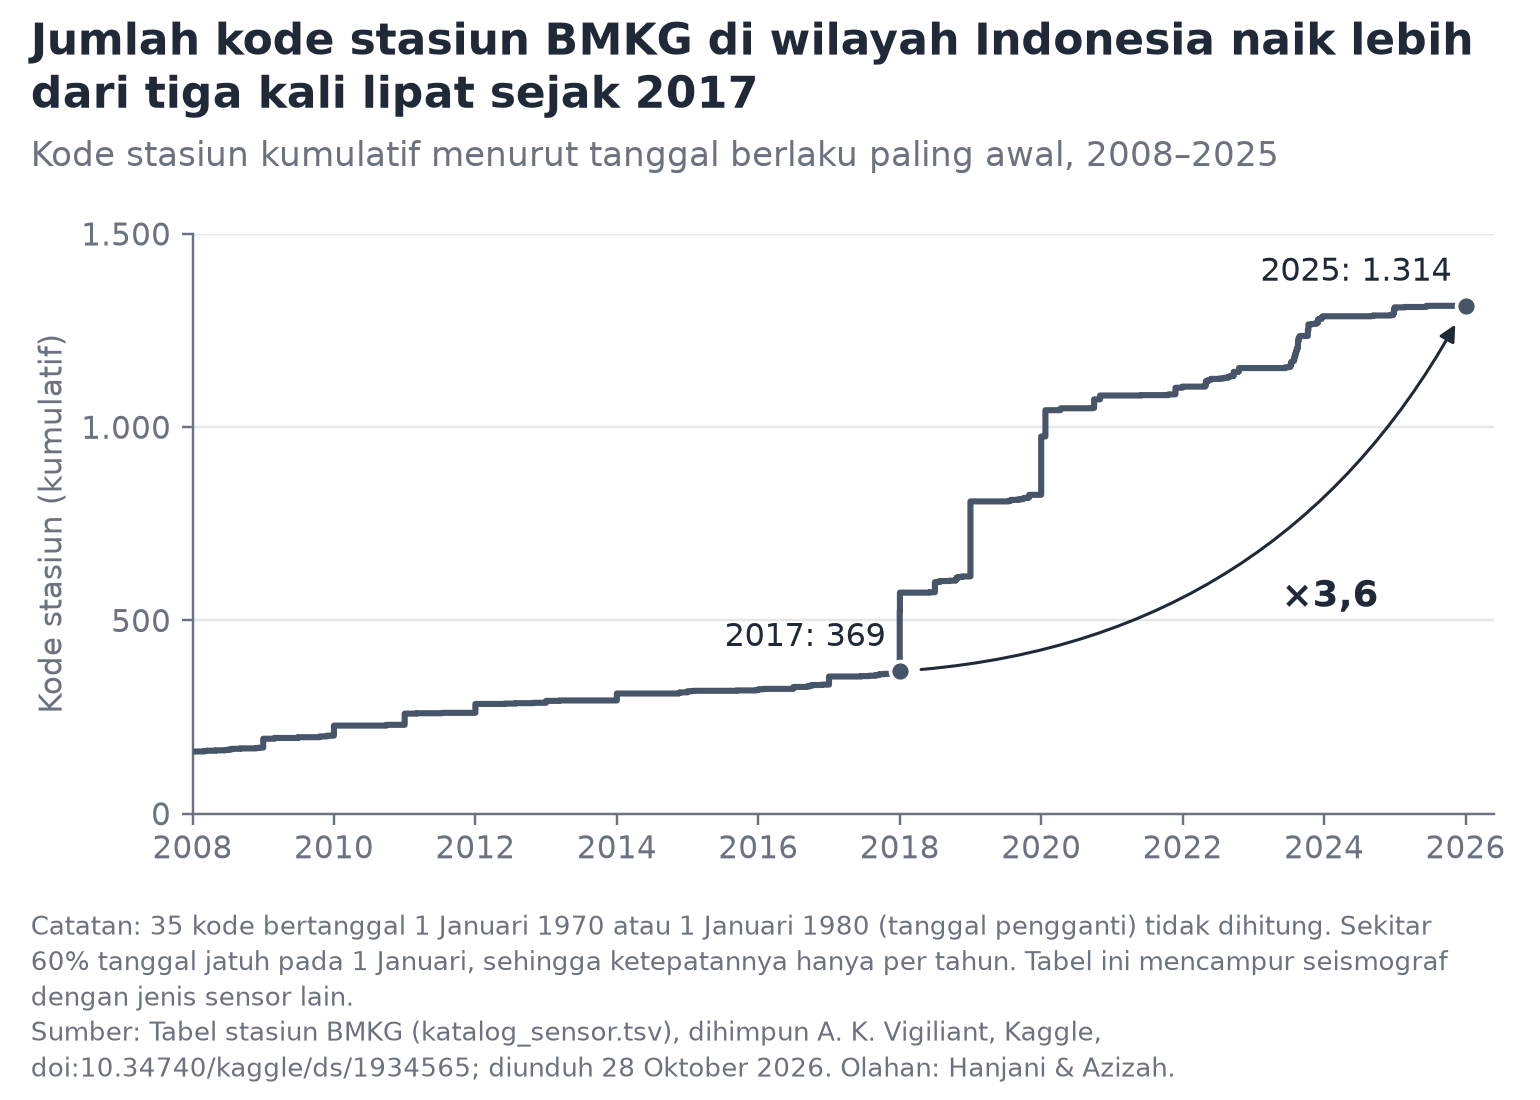

In [12]:
from src import figures

path = figures.fx()
print(path.relative_to(ROOT))
display(Image(filename=str(path), width=700))

## 6. Story page

Builds `story/site/index.html` from `story/content.md` (the group's text, verbatim) and prints the compliance check.

In [13]:
from src import build_story

report = build_story.build()

built story/site/index.html
compliance check (guide §3 Tahap 3 and §5):
  [OK] main message present, printed at the top (front matter `main_message`)
  [OK] main message is one sentence (found 1 sentence ending(s))
  [OK] title present
  [OK] authors present
  [OK] figure 1: file figures/f1_rilis_bmkg.png exists
  [OK] figure 1: finding title present
  [OK] figure 1: alt text present
  [OK] figure 2: file figures/f2_katalog_kelas_magnitudo.png exists
  [OK] figure 2: finding title present
  [OK] figure 2: alt text present
  [OK] figure 3: file figures/f3_distribusi_magnitudo.png exists
  [OK] figure 3: finding title present
  [OK] figure 3: alt text present
  [OK] figure 4: file figures/f4_bacaan_fase.png exists
  [OK] figure 4: finding title present
  [OK] figure 4: alt text present
  [OK] figure 5: file figures/f5_m4_per_bulan.png exists
  [OK] figure 5: finding title present
  [OK] figure 5: alt text present
  [OK] figure 6: file figures/f6_laju_m4_2026.png exists
  [OK] figure 6: f